In [1]:
# importing data set
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

RAW = {
    "kaub_level":   "../data/raw/water_level_15min_kaub.csv",
    "bingen_level": "../data/raw/bingen_water_level15_min.csv",
    "discharge":    "../data/raw/kaub_water_discharge.csv",
}
WEATHER_HOURLY = "../data/processed/kaub_water_weather_hourly.csv"
WEATHER_DAILY  = "../data/processed/kaub_water_weather_daily.csv"

OUT_HOURLY = "../data/processed/kaub_hydro_weather_hourly.csv"
OUT_DAILY  = "../data/processed/kaub_hydro_weather_daily.csv"

In [2]:
#Checking for the data
def load_raw(path: str, name: str) -> pd.Series:
    """Load and clean raw 15-minute water-level data from WSV."""

    # Read the raw CSV file using a semicolon as the separator
    d = pd.read_csv(path, sep=";")

    # Convert timestamps to datetime format
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # Convert water-level values to numeric and replace invalid values with NaN
    d["value"] = pd.to_numeric(d["value"], errors="coerce")

    # Generate a data quality report before removing duplicates
    report = {
        "rows": len(d),
        "duplicate timestamps": int(d["timestamp"].duplicated().sum()),
        "non-numeric values": int(d["value"].isna().sum()),
        "first": d["timestamp"].min(),
        "last": d["timestamp"].max(),
    }

    # Handle duplicate timestamps by calculating their mean water level
    # Sort chronologically and assign the station name to the Series
    s = d.groupby("timestamp")["value"].mean().sort_index().rename(name)

    # Record the number of observations after removing duplicate timestamps
    report["rows after dedup"] = len(s)

    # Display the data quality report for each station
    print(f"--- {name} ---")
    for k, v in report.items():
        print(f"  {k:22s}: {v}")

    # Return the cleaned water-level time series
    return s


# Load and clean raw water-level data for all stations defined in RAW
# Store the cleaned time series in a dictionary using station names as keys
series = {name: load_raw(path, name) for name, path in RAW.items()}

--- kaub_level ---
  rows                  : 935128
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-01 23:45:00
  rows after dedup      : 935024
--- bingen_level ---
  rows                  : 936714
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-18 12:15:00
  rows after dedup      : 936610
--- discharge ---
  rows                  : 936713
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-18 12:00:00
  rows after dedup      : 936609


In [3]:
# Create a dictionary to store duplicate timestamp information for each station
dup_check = {}

# Loop through all stations and their corresponding raw data files
for name, path in RAW.items():

    # Read the raw CSV file using a semicolon as the separator
    d = pd.read_csv(path, sep=";")

    # Convert timestamps to datetime format
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # Identify all rows with duplicate timestamps, including their first occurrence
    dups = d.loc[d["timestamp"].duplicated(keep=False), "timestamp"]

    # Summarize duplicate timestamp information for each station
    dup_check[name] = {

        # Count the total number of rows involved in duplicate timestamps
        "n duplicated rows": len(dups),

        # Count the number of unique dates affected by duplicate timestamps
        "distinct dates affected": dups.dt.date.nunique(),

        # Identify the months in which duplicate timestamps occur
        "months affected": sorted(dups.dt.month.unique().tolist()),

        # Identify the hours in which duplicate timestamps occur
        "hours affected": sorted(dups.dt.hour.unique().tolist()),

    }

# Convert the duplicate summary into a DataFrame for comparison across stations
pd.DataFrame(dup_check).T

,n duplicated rows,distinct dates affected,months affected,hours affected
kaub_level,208,26,[10],[2]
bingen_level,208,26,[10],[2]
discharge,208,26,[10],[2]


In [4]:
# Load the processed daily hydro-weather dataset
final_merged_df = pd.read_csv(
    "../data/processed/kaub_hydro_weather_daily.csv"
)

# Identify all numeric columns in the dataset
numeric_cols = final_merged_df.select_dtypes(include="number").columns

# Round numeric values to the nearest integer
# Convert them to nullable integers (Int64) to preserve missing values
final_merged_df[numeric_cols] = (
    final_merged_df[numeric_cols]
    .round()
    .astype("Int64")
)

# Display the first five rows of the updated dataset
final_merged_df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [5]:
#final merged data
final_merged_df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [6]:
#assigned to df 
df = final_merged_df

In [7]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Select all numeric columns
#numeric_cols = df.select_dtypes(include="number").columns

# Round values and convert to integers
#df[numeric_cols] = df[numeric_cols].round(0).astype("Int64")

# Sort by date
df = df.sort_values("date").reset_index(drop=True)

# Display the DataFrame
df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [8]:
# Count the number of days for each recorded number of available hourly observations
# Sort the results by the number of hours to identify days with missing or extra observations
df["hours_available"].value_counts().sort_index()

hours_available
23      28
24    9713
Name: count, dtype: Int64

In [9]:
# Select the main hydrological variables for correlation analysis
cols = [
    "water_level_mean",
    "bingen_level_mean",
    "discharge_mean"
]

# Calculate the Pearson correlation coefficients between the selected variables
# Identify the strength and direction of their linear relationships
df[cols].corr()

,water_level_mean,bingen_level_mean,discharge_mean
water_level_mean,1.000000,0.999100,0.995367
bingen_level_mean,0.999100,1.000000,0.992492
discharge_mean,0.995367,0.992492,1.000000


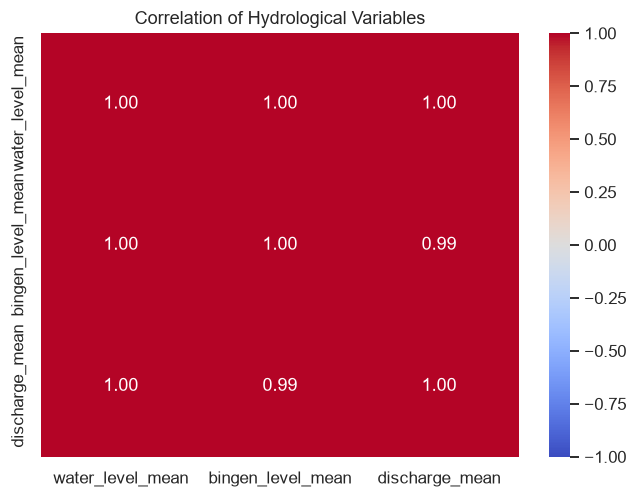

In [10]:
# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size for the correlation heatmap
plt.figure(figsize=(7, 5))

# Create a heatmap to visualize correlations between hydrological variables
sns.heatmap(
    df[cols].corr(),  # Calculate Pearson correlation coefficients
    annot=True,       # Display correlation values inside each cell
    fmt=".2f",        # Show correlation values with two decimal places
    cmap="coolwarm",  # Use a color gradient to represent correlation strength
    vmin=-1,          # Set the minimum correlation value
    vmax=1            # Set the maximum correlation value
)

# Add a descriptive title to the heatmap
plt.title("Correlation of Hydrological Variables")

# Display the correlation heatmap
plt.show()

In [11]:
# Calculate the correlation between Kaub water levels and lagged Bingen water levels
# Test lags from 0 to 7 days to examine the upstream-downstream relationship
for lag in range(0, 8):

    # Shift Bingen water levels by the specified number of days
    # Calculate the Pearson correlation with Kaub water levels
    corr = df["water_level_mean"].corr(
        df["bingen_level_mean"].shift(lag)
    )

    # Display the correlation coefficient for each lag
    print(f"Bingen lag {lag}: r = {corr:.3f}")

Bingen lag 0: r = 0.999
Bingen lag 1: r = 0.985
Bingen lag 2: r = 0.945
Bingen lag 3: r = 0.895
Bingen lag 4: r = 0.846
Bingen lag 5: r = 0.800
Bingen lag 6: r = 0.759
Bingen lag 7: r = 0.722


In [12]:
# Calculate the correlation between Kaub water levels and lagged discharge values
# Test lags from 0 to 7 days to examine their temporal relationship
for lag in range(0, 8):

    # Shift discharge values by the specified number of days
    # Calculate the Pearson correlation with Kaub water levels
    corr = df["water_level_mean"].corr(
        df["discharge_mean"].shift(lag)
    )

    # Display the correlation coefficient for each lag
    print(f"Discharge lag {lag}: r = {corr:.3f}")

Discharge lag 0: r = 0.995
Discharge lag 1: r = 0.977
Discharge lag 2: r = 0.934
Discharge lag 3: r = 0.881
Discharge lag 4: r = 0.829
Discharge lag 5: r = 0.782
Discharge lag 6: r = 0.740
Discharge lag 7: r = 0.702


In [13]:
# Calculate cumulative precipitation over different time windows
# Rolling sums capture the effect of recent rainfall on river water levels

# Calculate total precipitation over the current and previous 2 days
df["precip_3d"] = df["precipitation_sum"].rolling(3).sum()

# Calculate total precipitation over the current and previous 6 days
df["precip_7d"] = df["precipitation_sum"].rolling(7).sum()

# Calculate total precipitation over the current and previous 13 days
df["precip_14d"] = df["precipitation_sum"].rolling(14).sum()

# Calculate total precipitation over the current and previous 29 days
df["precip_30d"] = df["precipitation_sum"].rolling(30).sum()

In [14]:
# Calculate the correlation between water levels and cumulative precipitation over different time windows
# Identify which rainfall period has the strongest linear relationship with Kaub water levels

rain_cols = [
    "precipitation_sum",
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d"
]

df[rain_cols + ["water_level_mean"]].corr()["water_level_mean"]

precipitation_sum    0.059607
precip_3d            0.181170
precip_7d            0.390553
precip_14d           0.490115
precip_30d           0.524351
water_level_mean     1.000000
Name: water_level_mean, dtype: float64

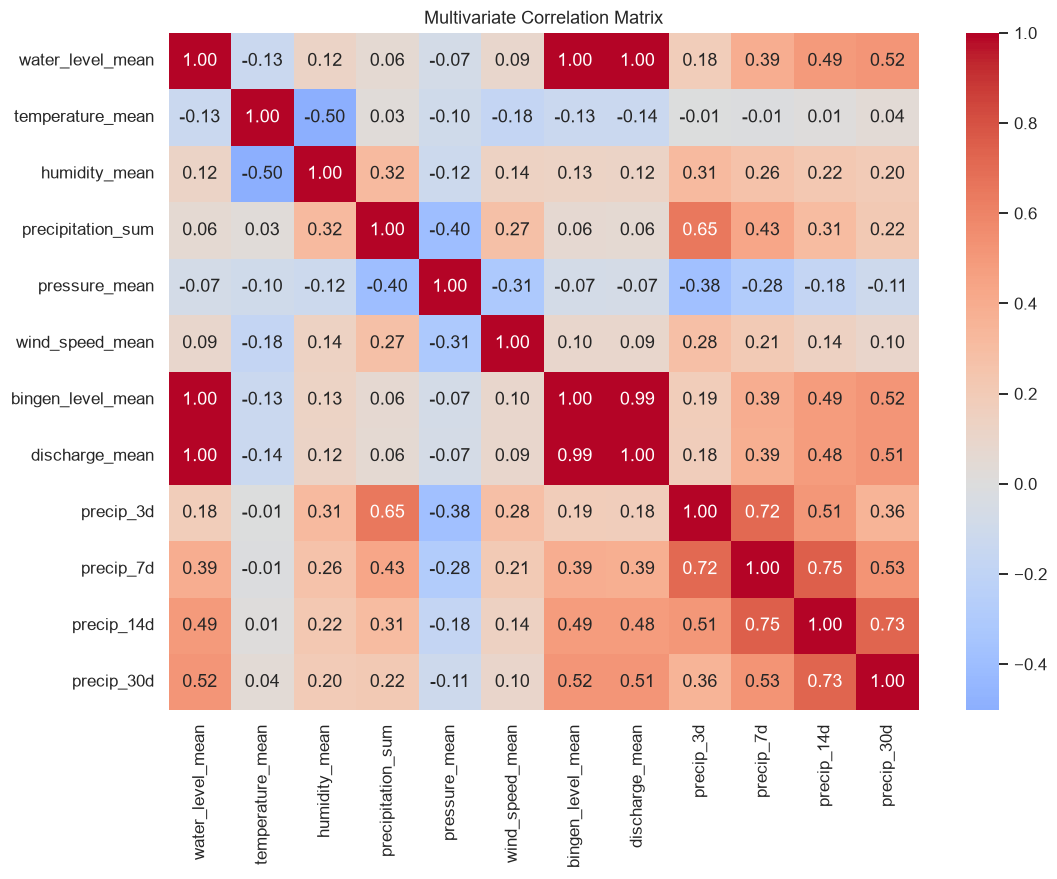

In [15]:
# Visualize the correlations among hydrological and weather variables
# Identify relationships with water levels and potential multicollinearity among features

features = [
    "water_level_mean",
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "bingen_level_mean",
    "discharge_mean",
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    df[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Multivariate Correlation Matrix")

plt.show()

In [16]:
#Fixing the target feature
TARGET = "water_level_mean"

In [17]:
# Kaub water-level lags
df["level_lag_1"] = df["water_level_mean"].shift(1)
df["level_lag_2"] = df["water_level_mean"].shift(2)
df["level_lag_3"] = df["water_level_mean"].shift(3)
df["level_lag_7"] = df["water_level_mean"].shift(7)
df["level_lag_14"] = df["water_level_mean"].shift(14)

In [18]:
# Calculate the daily change in Kaub water level compared to the previous day

df["level_change_1d"] = df["water_level_mean"].diff(1)

In [19]:
# Create lagged Bingen water-level features for the previous 1, 2, and 3 days
# Capture the influence of historical upstream water levels on Kaub

df["bingen_lag_1"] = df["bingen_level_mean"].shift(1)

df["bingen_lag_2"] = df["bingen_level_mean"].shift(2)

df["bingen_lag_3"] = df["bingen_level_mean"].shift(3)

In [20]:
# Create lagged discharge features for the previous 1, 2, and 3 days
# Capture the influence of historical river discharge on Kaub water levels

df["discharge_lag_1"] = df["discharge_mean"].shift(1)

df["discharge_lag_2"] = df["discharge_mean"].shift(2)

df["discharge_lag_3"] = df["discharge_mean"].shift(3)

In [21]:
# Calculate the daily change in river discharge compared to the previous day

df["discharge_change_1d"] = df["discharge_mean"].diff(1)

In [22]:
# Calculate cumulative precipitation over 3, 7, 14, and 30 days
# Capture the influence of recent rainfall on river water levels

df["precip_3d"] = df["precipitation_sum"].rolling(3).sum()

df["precip_7d"] = df["precipitation_sum"].rolling(7).sum()

df["precip_14d"] = df["precipitation_sum"].rolling(14).sum()

df["precip_30d"] = df["precipitation_sum"].rolling(30).sum()

In [23]:
# Calculate the average temperature over 3 and 7 days
# Capture short-term temperature trends that may influence river water levels

df["temp_3d"] = df["temperature_mean"].rolling(3).mean()

df["temp_7d"] = df["temperature_mean"].rolling(7).mean()

In [24]:
# Create cyclical day-of-year features using sine and cosine transformations
# Capture seasonal patterns while preserving the continuity between the end and start of each year

import numpy as np

df["day_of_year"] = df["date"].dt.dayofyear

df["doy_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["doy_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

In [25]:
# Create target variables for forecasting Kaub water levels from 1 to 7 days ahead
# Shift water levels backward to align each future target with the current day's features

for h in range(1, 8):

    df[f"target_day_{h}"] = df["water_level_mean"].shift(-h)

In [26]:
# Define the input features for multivariate water-level forecasting
# Include historical river conditions, weather patterns, and seasonal variations

FEATURES = [
    # Kaub history
    "level_lag_1",
    "level_lag_2",
    "level_lag_3",
    "level_lag_7",
    "level_lag_14",
    "level_change_1d",

    # Upstream Bingen
    "bingen_lag_1",
    "bingen_lag_2",
    "bingen_lag_3",

    # Discharge
    "discharge_lag_1",
    "discharge_lag_2",
    "discharge_lag_3",
    "discharge_change_1d",

    # Rainfall memory
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d",

    # Temperature
    "temp_3d",
    "temp_7d",

    # Seasonality
    "doy_sin",
    "doy_cos"
]

In [27]:
# Define the target columns for predicting Kaub water levels from 1 to 7 days ahead

Target_cols = [
    f"target_day_{h}"
    for h in range(1, 8)
]

In [28]:
# Calculate correlations between input features and future water levels for all seven forecast horizons
# Identify how the linear relationship between each feature and the target changes over time

TARGETS = [
    f"target_day_{h}"
    for h in range(1, 8)
]

corr_horizons = df[
    FEATURES + TARGETS
].corr().loc[FEATURES, TARGETS]

display(corr_horizons.round(3))

,target_day_1,target_day_2,target_day_3,target_day_4,target_day_5,target_day_6,target_day_7
level_lag_1,0.941,0.890,0.840,0.794,0.753,0.716,0.684
level_lag_2,0.890,0.840,0.794,0.753,0.716,0.684,0.655
level_lag_3,0.840,0.794,0.753,0.716,0.684,0.655,0.631
level_lag_7,0.684,0.655,0.631,0.611,0.594,0.580,0.567
level_lag_14,0.555,0.544,0.533,0.523,0.514,0.505,0.494
level_change_1d,0.223,0.269,0.267,0.244,0.218,0.194,0.173
bingen_lag_1,0.945,0.895,0.846,0.800,0.759,0.722,0.690
bingen_lag_2,0.895,0.846,0.800,0.759,0.722,0.690,0.661
bingen_lag_3,0.846,0.800,0.759,0.722,0.690,0.661,0.636
discharge_lag_1,0.934,0.881,0.829,0.782,0.740,0.702,0.669


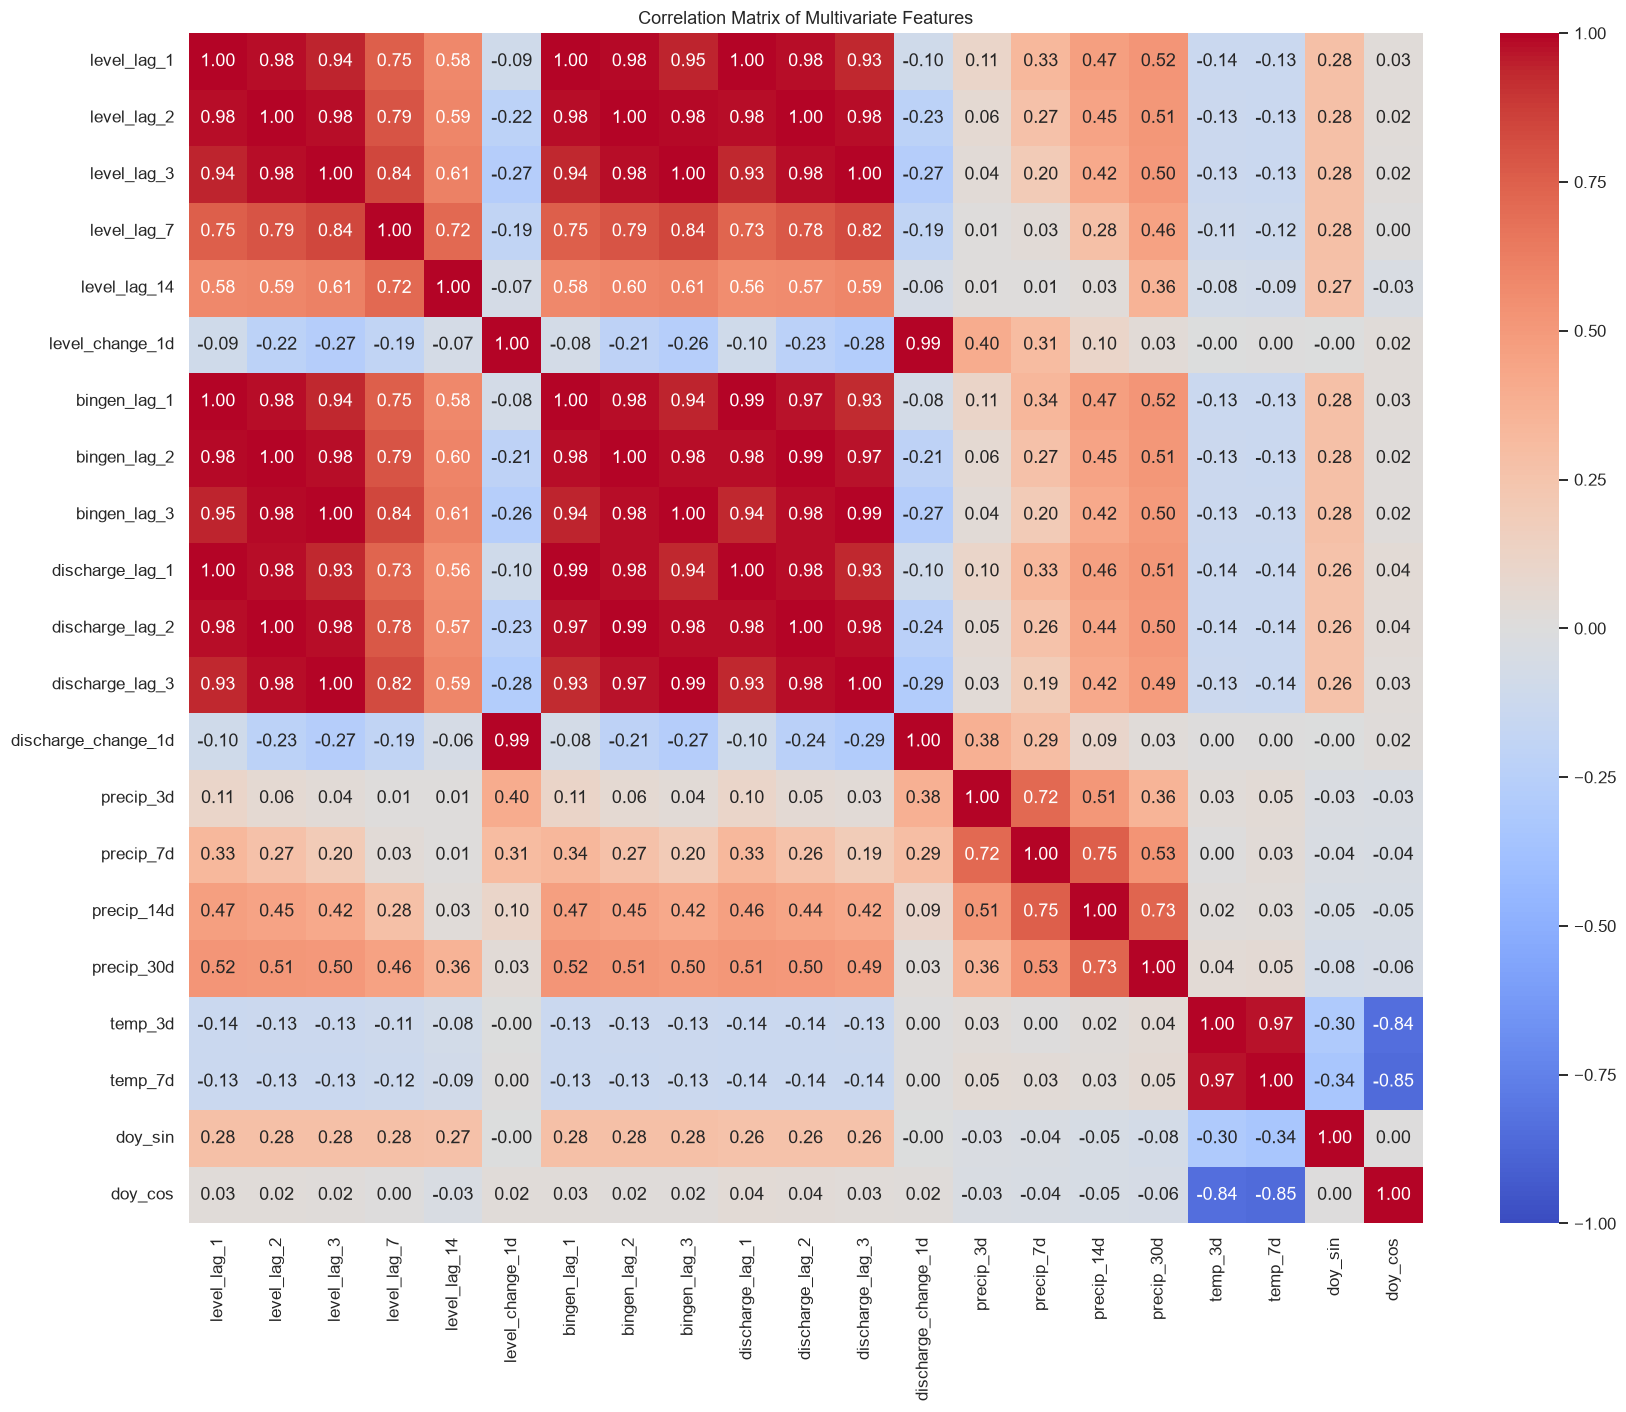

In [29]:
# Heatmap : Correlation between engineered features
feature_corr = df[FEATURES].corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Matrix of Multivariate Features"
)

plt.tight_layout()
plt.show()

In [30]:
model_df = df[
    ["date"] + FEATURES + TARGETS
].dropna().copy()

print(model_df.shape)
print(model_df["date"].min())
print(model_df["date"].max())

(9705, 29)
2000-01-30 00:00:00
2026-08-25 00:00:00


In [31]:
# Print features
print("FEATURES:", FEATURES)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nMissing features:")
print([col for col in FEATURES if col not in df.columns])

FEATURES: ['level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d', 'doy_sin', 'doy_cos']

Available columns:
['date', 'water_level_mean', 'water_level_min', 'water_level_max', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'pressure_mean', 'wind_speed_mean', 'bingen_level_mean', 'bingen_level_min', 'bingen_level_max', 'discharge_mean', 'discharge_min', 'discharge_max', 'hours_available', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'temp_3d', 'temp_7d', 'day_of_year', 'doy_sin', 'd

In [32]:
# Kaub water level lag features
LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

for lag in LAGS:
    df[f"lag_{lag}"] = (
        df["water_level_mean"].shift(lag)
    )

In [33]:
# Seven-day forecasting targets
TARGETS = []

for h in range(1, 8):

    target_col = f"target_day_{h}"

    df[target_col] = (
        df["water_level_mean"].shift(-h)
    )

    TARGETS.append(target_col)

In [34]:
# Check whether all required columns exist
missing_cols = [
    col for col in FEATURES + TARGETS
    if col not in df.columns
]

if missing_cols:
    print("Missing columns:", missing_cols)

else:
    # Calculate correlations
    corr_horizons = (
        df[FEATURES + TARGETS]
        .corr()
        .loc[FEATURES, TARGETS]
    )

    display(corr_horizons.round(3))

,target_day_1,target_day_2,target_day_3,target_day_4,target_day_5,target_day_6,target_day_7
level_lag_1,0.941,0.890,0.840,0.794,0.753,0.716,0.684
level_lag_2,0.890,0.840,0.794,0.753,0.716,0.684,0.655
level_lag_3,0.840,0.794,0.753,0.716,0.684,0.655,0.631
level_lag_7,0.684,0.655,0.631,0.611,0.594,0.580,0.567
level_lag_14,0.555,0.544,0.533,0.523,0.514,0.505,0.494
level_change_1d,0.223,0.269,0.267,0.244,0.218,0.194,0.173
bingen_lag_1,0.945,0.895,0.846,0.800,0.759,0.722,0.690
bingen_lag_2,0.895,0.846,0.800,0.759,0.722,0.690,0.661
bingen_lag_3,0.846,0.800,0.759,0.722,0.690,0.661,0.636
discharge_lag_1,0.934,0.881,0.829,0.782,0.740,0.702,0.669


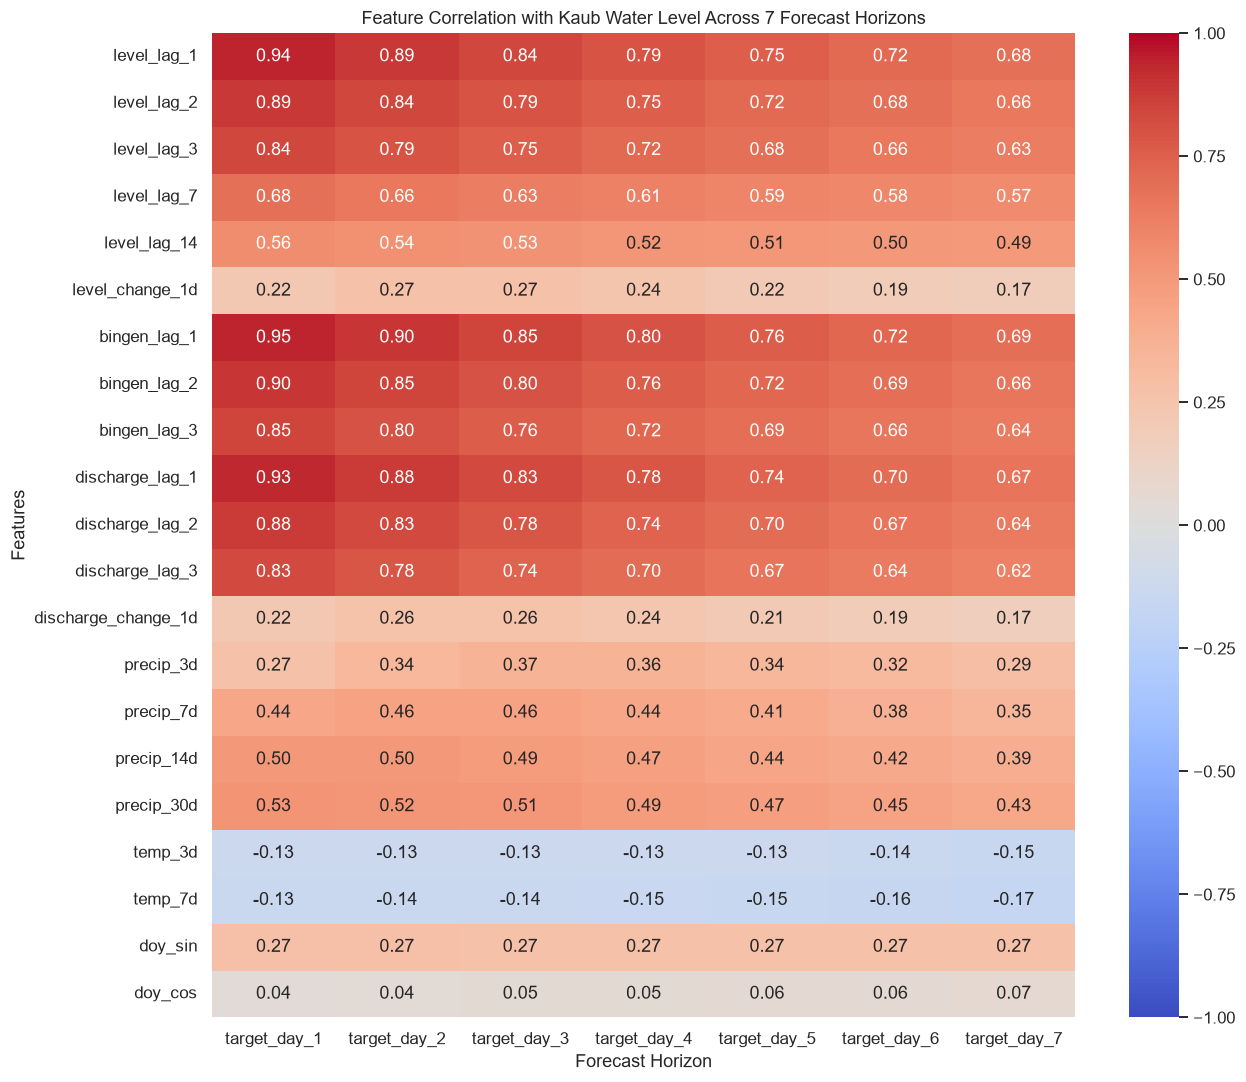

In [35]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_horizons,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Feature Correlation with Kaub Water Level "
    "Across 7 Forecast Horizons"
)

plt.xlabel("Forecast Horizon")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [36]:
# Prepare the univariate time-series dataset using historical Kaub water levels
# Create lag features and a target variable for forecasting water levels 7 days ahead

HORIZON = 7
H = HORIZON

LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

# Select Kaub daily mean water level
s = df["water_level_mean"]

data = pd.DataFrame(index=s.index)

for L in LAGS:
    data[f"lag_{L}"] = s.shift(L)

data["target"] = s.shift(-H)

FEATURES = [f"lag_{L}" for L in LAGS]

data.head(35)

,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14,lag_21,lag_28,target
0,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,305
1,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,294
2,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,285
3,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,282
4,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,284
5,311,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,272
6,304,311,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,260
7,305,304,311,328,346,368,401,439,<NA>,<NA>,<NA>,250
8,294,305,304,311,328,346,368,401,<NA>,<NA>,<NA>,238
9,285,294,305,304,311,328,346,368,<NA>,<NA>,<NA>,226


In [37]:
# Validate the alignment of lag features and the 7-day-ahead target
# Confirm that the current water level and future target correspond to the correct dates

i = 400

row = data.iloc[i]

assert row["lag_0"] == s.iloc[i]

assert row["target"] == s.iloc[i + H]

print(
    f"On {data.index[i]}: "
    f"today={row['lag_0']:.2f}, "
    f"target(+{H}d)={row['target']:.2f}"
)

On 400: today=230.00, target(+7d)=308.00


In [38]:
# Check the index type and values to verify the time-series date index

print(type(data.index))

print(data.index)

<class 'pandas.RangeIndex'>
RangeIndex(start=0, stop=9741, step=1)


In [39]:
# Set the date as a sorted datetime index for time-series analysis
# Select the daily mean Kaub water level as the target series

df["date"] = pd.to_datetime(df["date"])

df = df.set_index("date").sort_index()

s = df["water_level_mean"]

In [40]:
# Define the forecast horizon and test period, then verify the dataset structure
# Check the date index, input features, data dimensions, and target availability

H = 7

TEST_YEARS = 3

print("Index type:", type(data.index))

print("Features:", FEATURES)

print("Data shape:", data.shape)

print("Target exists:", "target" in data.columns)

print("First date:", data.index.min())

print("Last date:", data.index.max())

Index type: <class 'pandas.RangeIndex'>
Features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28']
Data shape: (9741, 12)
Target exists: True
First date: 0
Last date: 9740


In [41]:
print(df.columns.tolist())
print(df.head(3))

['water_level_mean', 'water_level_min', 'water_level_max', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'pressure_mean', 'wind_speed_mean', 'bingen_level_mean', 'bingen_level_min', 'bingen_level_max', 'discharge_mean', 'discharge_min', 'discharge_max', 'hours_available', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'temp_3d', 'temp_7d', 'day_of_year', 'doy_sin', 'doy_cos', 'target_day_1', 'target_day_2', 'target_day_3', 'target_day_4', 'target_day_5', 'target_day_6', 'target_day_7', 'lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28']
            water_level_mean  water_level_min  water_level_max  temperature_mean  humidity_mean  precipitation_sum  rain_sum  \
date     

In [42]:
print(type(df.index))

<class 'pandas.DatetimeIndex'>


In [43]:
df.index = pd.to_datetime(df.index)
df = df.sort_index()

In [44]:
# Prepare the multivariate dataset with a datetime index and selected input features
# Set the 7-day-ahead water level as the target and verify the dataset structure

import pandas as pd

df.index = pd.to_datetime(df.index)
df = df.sort_index()

FEATURES = [
    "lag_0", "lag_1", "lag_2", "lag_3",
    "lag_7", "lag_14", "lag_28",
    "precip_3d", "precip_7d", "precip_14d", "precip_30d",
    "temp_3d", "temp_7d",
    "bingen_lag_1", "bingen_lag_2", "bingen_lag_3",
    "doy_sin", "doy_cos"
]

data = df[FEATURES + ["target_day_7"]].copy()
data = data.rename(columns={"target_day_7": "target"})

print("df index:", type(df.index))
print("data index:", type(data.index))
print("Last date:", data.index.max())

df index: <class 'pandas.DatetimeIndex'>
data index: <class 'pandas.DatetimeIndex'>
Last date: 2026-09-01 00:00:00


In [45]:
# Split the time-series data into training and test sets using the last 3 years for testing
# Apply a 7-day embargo to prevent overlapping forecast targets and verify temporal separation

H = 7

TEST_YEARS = 3

split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)

train = data.loc[:split_date - pd.Timedelta(days=H)].dropna()

test = data.loc[split_date + pd.Timedelta(days=1):].dropna()

X_train, y_train = train[FEATURES], train["target"]

X_test, y_test = test[FEATURES], test["target"]

print(f"train: {train.index.min().date()} → {train.index.max().date()} n={len(train)}")

print(f"test : {test.index.min().date()} → {test.index.max().date()} n={len(test)}")

assert train.index.max() + pd.Timedelta(days=H) < test.index.min(), "embargo violated"

train: 2000-01-30 → 2023-08-25 n=8609
test : 2023-09-02 → 2026-08-25 n=1089


In [46]:
# Split the training data into model-fitting and validation sets, using the last 2 years for validation
# Apply a 7-day embargo to prevent target overlap and ensure temporal separation

VALID_YEARS = 2

validation_start = (
    train.index.max() - pd.DateOffset(years=VALID_YEARS)
    + pd.Timedelta(days=1)
)

train_fit = train.loc[
    :validation_start - pd.Timedelta(days=H + 1)
].copy()

validation = train.loc[
    validation_start:
].copy()

print(
    f"Model fitting: {train_fit.index.min().date()} → "
    f"{train_fit.index.max().date()} | n={len(train_fit)}"
)

print(
    f"Validation:    {validation.index.min().date()} → "
    f"{validation.index.max().date()} | n={len(validation)}"
)

assert (
    train_fit.index.max() + pd.Timedelta(days=H)
    < validation.index.min()
), "Validation embargo violated"

Model fitting: 2000-01-30 → 2021-08-18 | n=7872
Validation:    2021-08-26 → 2023-08-25 | n=730


In [47]:
import pandas as pd
import numpy as np

# Actual water level 7 days ahead
y_val = validation["target"]

# Baseline prediction: today's observed water level
pred_baseline = validation["lag_0"].copy()

# Positive bias = overprediction; negative bias = underprediction
errors = pred_baseline - y_val

baseline_mae = errors.abs().mean()
baseline_rmse = np.sqrt((errors ** 2).mean())
baseline_bias = errors.mean()

baseline_results = pd.DataFrame([{
    "Model": "Persistence baseline",
    "Horizon (days)": H,
    "Samples": len(y_val),
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    #"R2" : r2_score(y_val, pred_baseline),
    "Bias": baseline_bias,
    "Skill vs persistence (MAE)": 0.0
}])

display(baseline_results.round(3))

,Model,Horizon (days),Samples,MAE,RMSE,Bias,Skill vs persistence (MAE)
0,Persistence baseline,7,730,45.237,64.235,0.314,0.0


In [48]:
# Define feature groups to evaluate the contribution of additional weather and hydrological variables
# Compare different feature combinations to identify which inputs improve water-level forecasting

feature_groups = {
    "Kaub only": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28"
    ],

    "Kaub + precipitation": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28",
        "precip_3d", "precip_7d",
        "precip_14d", "precip_30d"
    ],

    "Kaub + precipitation + temperature": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28",
        "precip_3d", "precip_7d",
        "precip_14d", "precip_30d",
        "temp_3d", "temp_7d"
    ],

     #"Kaub + weather + Bingen + discharge": [
      #  "lag_0", "lag_1", "lag_2", "lag_3",
       # "lag_7", "lag_14", "lag_28",

        # Precipitation
        #"precip_3d", "precip_7d",
        #"precip_14d", "precip_30d",

        # Temperature
        #"temp_3d", "temp_7d",

        # Bingen water level
        #"bingen_lag_1", "bingen_lag_2",
        #"bingen_lag_3", "bingen_lag_7",

        # Kaub discharge
        #"discharge_lag_1", "discharge_lag_3",
        #"discharge_lag_7", "discharge_7d_mean"
    #],

    "All selected features": FEATURES
}

In [49]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for group_name, columns in feature_groups.items():

    model = LinearRegression()

    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    predictions = model.predict(validation[columns])
    y_valid = validation["target"]

    mae = mean_absolute_error(y_valid, predictions)
    rmse = mean_squared_error(y_valid, predictions) ** 0.5
    r2 = r2_score(y_valid, predictions)
    #bias = np.mean(predictions - validation["target"]

    n = len(y_valid)
    p = len(columns)

    adjusted_r2 = (
        1 - (1 - r2) * (n - 1) / (n - p - 1)
        if n > p + 1 else float("nan")
    )

    bias = np.mean(predictions - y_valid.to_numpy())

    results.append({
        "Feature group": group_name,
        "Number of features": p,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
        "Bias":bias
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R²,Bias
0,Kaub only,7,45.446,57.376,0.409,11.681
1,Kaub + precipitation,11,46.275,58.294,0.390,15.044
2,Kaub + precipitation + temperature,13,45.169,56.572,0.425,15.432
3,All selected features,18,45.000,57.263,0.411,15.507


In [50]:
# Evaluate the persistence baseline by assuming the water level remains unchanged after 7 days
# Calculate MAE and RMSE to compare baseline performance with the machine learning models

persistence_predictions = validation["lag_0"]

persistence_mae = mean_absolute_error(
    validation["target"],
    persistence_predictions
)

persistence_rmse = mean_squared_error(
    validation["target"],
    persistence_predictions
) ** 0.5

print(f"Persistence MAE:  {persistence_mae:.2f} cm")

print(f"Persistence RMSE: {persistence_rmse:.2f} cm")

Persistence MAE:  45.24 cm
Persistence RMSE: 64.23 cm


In [51]:
# Calculate the relative improvement in MAE compared with the persistence baseline
# Positive skill indicates better forecasting performance than persistence

results_df["Skill vs persistence"] = (
    1 - results_df["MAE"] / persistence_mae
)

display(results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R²,Bias,Skill vs persistence
0,Kaub only,7,45.446,57.376,0.409,11.681,-0.005
1,Kaub + precipitation,11,46.275,58.294,0.390,15.044,-0.023
2,Kaub + precipitation + temperature,13,45.169,56.572,0.425,15.432,0.002
3,All selected features,18,45.000,57.263,0.411,15.507,0.005


1. Modeling : LightGBM

In [52]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

In [53]:
# Store results and trained models
lgbm_results = []
lgbm_models = {}

# Loop through each feature group
for group_name, columns in feature_groups.items():

    # Initialize LightGBM model
    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.01,
        max_depth=6,
        num_leaves=7,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=1.0,
        reg_alpha=0.2,
        reg_lambda=5.0,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    )

    # Train model
    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    # Predict on validation data
    predictions = model.predict(
        validation[columns]
    )

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["target"],
            predictions
        )
    )

    R2 = r2_score(
        validation["target"],
        predictions
    )

    bias = np.mean(predictions - y_valid.to_numpy())

    # Calculate skill vs persistence
    #skill = 1 - mae / persistence_mae

    # Store results
    lgbm_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": R2,
        "Bias" : bias
        #"Skill vs persistence": skill
    })

    # Store trained model
    lgbm_models[group_name] = model

# Create results DataFrame
lgbm_results_df = pd.DataFrame(lgbm_results)

# Display results
display(lgbm_results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R_squared,Bias
0,Kaub only,7,47.001,59.404,0.366,11.175
1,Kaub + precipitation,11,45.955,58.727,0.381,13.407
2,Kaub + precipitation + temperature,13,44.554,56.804,0.421,13.653
3,All selected features,18,44.758,57.161,0.413,15.228


2. Random Forest :

In [54]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Actual targets and persistence baseline
y_valid = validation["target"].to_numpy()

persistence_mae = mean_absolute_error(
    y_valid, validation["lag_0"]
)

# Store results and trained models
rf_results = []
rf_models = {}

for group_name, columns in feature_groups.items():

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )

    # Train on the earlier training period
    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    # Predict on the later validation period
    predictions = model.predict(validation[columns])

    # Validation metrics
    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)

    # Positive bias = overprediction; negative = underprediction
    bias = np.mean(predictions - y_valid)

    skill = (
        1 - mae / persistence_mae
        if persistence_mae > 0 else np.nan
    )

    rf_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": r2,
        "Bias": bias,
        "Skill vs persistence": skill
    })

    rf_models[group_name] = model

rf_results_df = (
    pd.DataFrame(rf_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(rf_results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R_squared,Bias,Skill vs persistence
0,Kaub + precipitation + temperature,13,45.497,57.900,0.398,14.381,-0.006
1,Kaub only,7,46.592,59.908,0.356,9.880,-0.030
2,All selected features,18,46.864,59.292,0.369,16.707,-0.036
3,Kaub + precipitation,11,47.249,61.059,0.331,13.887,-0.044


In [55]:
best_rf_group = rf_results_df.iloc[0]["Feature group"]
best_rf_model = rf_models[best_rf_group]

print("Best feature group:", best_rf_group)
print(f"Validation MAE: {rf_results_df.iloc[0]['MAE']:.3f} cm")

Best feature group: Kaub + precipitation + temperature
Validation MAE: 45.497 cm


3. Modeling : XGBoost

In [56]:
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np

# Train and evaluate XGBoost models using different feature groups
# Compare MAE, RMSE, R², Bias, and skill against the persistence baseline

xgb_results = []
xgb_models = {}

for group_name, columns in feature_groups.items():

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    predictions = model.predict(validation[columns])

    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = mean_squared_error(
        validation["target"],
        predictions
    ) ** 0.5

    R2 = r2_score(
        validation["target"],
        predictions
    )

    bias = np.mean(
        predictions - validation["target"]
    )

    xgb_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_square": R2,
        "Bias": bias
    })

    xgb_models[group_name] = model

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R_square,Bias
0,Kaub only,7,46.481,59.740,0.359,10.420
1,Kaub + precipitation,11,45.419,59.540,0.364,11.136
2,Kaub + precipitation + temperature,13,43.481,56.213,0.433,11.281
3,All selected features,18,44.274,56.765,0.421,14.919


In [57]:
from sklearn.base import clone

# 1. Select the best feature group using validation results
best_group = xgb_results_df.loc[
    xgb_results_df["MAE"].idxmin(), "Feature group"
]

columns = xgb_models[best_group].get_booster().feature_names

# 2. Refit the selected model on all pre-test training data
final_xgb = clone(xgb_models[best_group])

final_xgb.fit(
    train[columns],
    train["target"]
)

# 3. Predict the held-out test data
y_test = test["target"]
test_predictions = final_xgb.predict(test[columns])

# Persistence baseline on exactly the same test rows
persistence_predictions = test["lag_0"]

test_mae = mean_absolute_error(y_test, test_predictions)
persistence_mae = mean_absolute_error(
    y_test, persistence_predictions
)

# 4. Display test metrics
test_results = pd.DataFrame([{
    "Model": "XGBoost",
    "Feature group": best_group,
    "Test samples": len(y_test),
    "MAE (cm)": test_mae,
    "RMSE (cm)": mean_squared_error(
        y_test, test_predictions
    ) ** 0.5,
    "R²": r2_score(y_test, test_predictions),
    "Bias (cm)": np.mean(
        test_predictions - y_test.to_numpy()
    ),
    "Persistence MAE (cm)": persistence_mae,
    "Skill vs persistence": (
        1 - test_mae / persistence_mae
        if persistence_mae > 0 else np.nan
    )
}])

display(test_results.round(3))

,Model,Feature group,Test samples,MAE (cm),RMSE (cm),R²,Bias (cm),Persistence MAE (cm),Skill vs persistence
0,XGBoost,Kaub + precipitation + temperature,1089,47.488,63.947,0.675,-0.213,50.816,0.066


In [58]:
# Generate predictions for the TEST data using the final model
columns = final_xgb.get_booster().feature_names
test_predictions = final_xgb.predict(test[columns])

# Build the error table using the same test rows
errors = pd.DataFrame({
    "Actual": test["target"],
    "Predicted": test_predictions,
    "Persistence": test["lag_0"]
}, index=test.index)

# Positive error = overprediction
errors["Error"] = errors["Predicted"] - errors["Actual"]
errors["Absolute error"] = errors["Error"].abs()

display(errors.head())

,Actual,Predicted,Persistence,Error,Absolute error
date,,,,,
2023-09-02,161,246.946487,274,85.946487,85.946487
2023-09-03,157,212.879776,249,55.879776,55.879776
2023-09-04,151,190.392471,227,39.392471,39.392471
2023-09-05,146,191.636642,205,45.636642,45.636642
2023-09-06,147,198.749847,188,51.749847,51.749847


In [59]:


# Define water conditions using ACTUAL water levels
low_threshold = 77
high_threshold = train["target"].quantile(0.90)

errors["Condition"] = np.select(
    [
        errors["Actual"] <= low_threshold,
        errors["Actual"] >= high_threshold
    ],
    ["Low water", "High water"],
    default="Normal water"
)

# Analyse all test days and each water condition
groups = [("All levels", errors)] + [
    (condition, errors.loc[errors["Condition"] == condition])
    for condition in ["Low water", "Normal water", "High water"]
]

results = []

for condition, subset in groups:
    if subset.empty:
        continue

    error = subset["Error"]  # predicted − actual
    baseline_error = subset["Persistence"] - subset["Actual"]

    mae = error.abs().mean()
    baseline_mae = baseline_error.abs().mean()

    results.append({
        "Condition": condition,
        "Days": len(subset),
        "MAE (cm)": mae,
        "RMSE (cm)": np.sqrt((error ** 2).mean()),
        "Bias (cm)": error.mean(),
        "Overprediction (%)": (error > 0).mean() * 100,
        "Persistence MAE (cm)": baseline_mae,
        "Skill vs persistence": (
            1 - mae / baseline_mae
            if baseline_mae > 0 else np.nan
        )
    })

error_summary = pd.DataFrame(results)
display(error_summary.round(2))

,Condition,Days,MAE (cm),RMSE (cm),Bias (cm),Overprediction (%),Persistence MAE (cm),Skill vs persistence
0,All levels,1089,47.49,63.95,-0.21,60.70,50.82,0.07
1,Low water,55,35.90,42.12,35.07,96.36,23.58,-0.52
2,Normal water,882,39.71,49.05,11.58,65.99,43.81,0.09
3,High water,152,96.83,121.22,-81.41,17.11,101.34,0.04


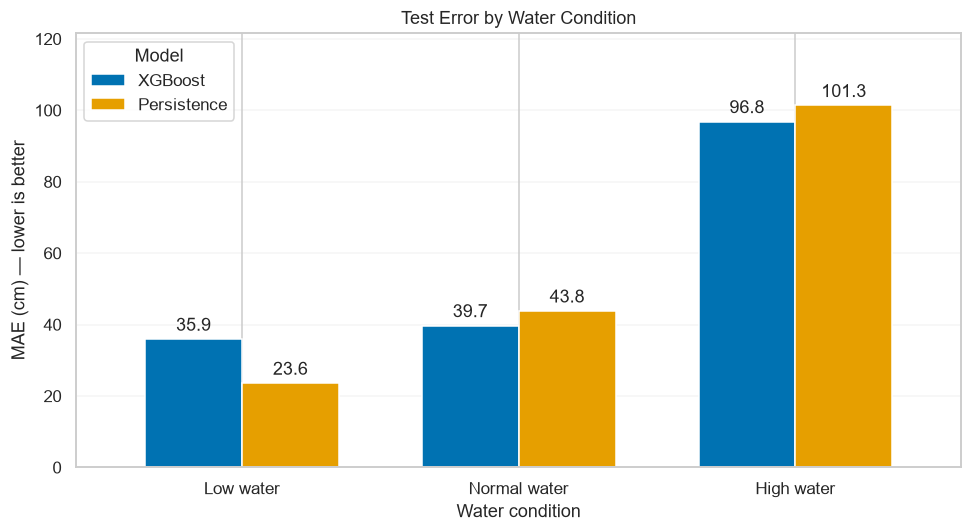

In [60]:
import matplotlib.pyplot as plt

plot_data = error_summary.set_index("Condition").loc[
    ["Low water", "Normal water", "High water"],
    ["MAE (cm)", "Persistence MAE (cm)"]
]

plot_data.columns = ["XGBoost", "Persistence"]

ax = plot_data.plot.bar(
    figsize=(9, 5),
    color=["#0072B2", "#E69F00"],
    rot=0,
    width=0.7
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.set(
    title="Test Error by Water Condition",
    xlabel="Water condition",
    ylabel="MAE (cm) — lower is better"
)

ax.set_ylim(0, plot_data.to_numpy().max() * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Model")

plt.tight_layout()
plt.show()

In [61]:
errors["Target date"] = errors.index + pd.Timedelta(days=7)

display(
    errors.nlargest(10, "Absolute error")[
        ["Target date", "Actual", "Predicted",
         "Error", "Absolute error", "Condition"]
    ].round(2)
)

C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_24220\864286116.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Target date,Actual,Predicted,Error,Absolute error,Condition
date,,,,,,
2023-11-12,2023-11-19,520,225.500000,-294.5,294.5,High water
2024-05-29,2024-06-05,645,357.309998,-287.69,287.69,High water
2024-05-28,2024-06-04,634,362.329987,-271.67,271.67,High water
2023-11-13,2023-11-20,527,271.059998,-255.94,255.94,High water
2023-11-11,2023-11-18,499,243.199997,-255.8,255.8,High water
2023-12-08,2023-12-15,581,332.540009,-248.46,248.46,High water
2026-02-08,2026-02-15,406,167.089996,-238.91,238.91,High water
2023-12-19,2023-12-26,583,348.600006,-234.4,234.4,High water
2025-01-01,2025-01-08,395,165.509995,-229.49,229.49,High water


In [62]:
group = "Kaub + precipitation + temperature"

model = xgb_models[group]
columns = feature_groups[group]

comparison = []

for name, subset in [
    ("Training", train_fit),
    ("Validation", validation)
]:
    actual = subset["target"].to_numpy()
    predicted = model.predict(subset[columns])
    errors = predicted - actual

    comparison.append({
        "Dataset": name,
        "Samples": len(actual),
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "Bias": errors.mean()
    })

display(pd.DataFrame(comparison).round(3))

,Dataset,Samples,MAE,RMSE,Bias
0,Training,7872,36.826,50.495,0.007
1,Validation,730,43.481,56.213,11.281


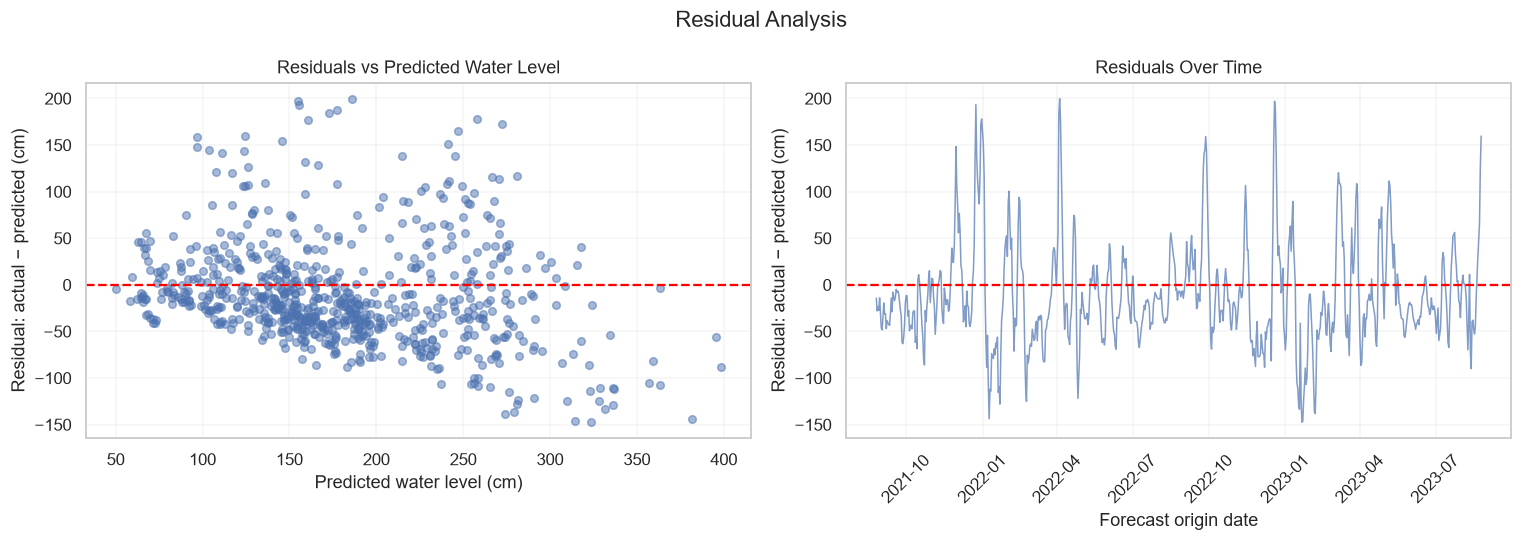

In [63]:


# Select the feature group with the lowest validation MAE
best_group = xgb_results_df.loc[
    xgb_results_df["MAE"].idxmin(), "Feature group"
]

best_model = xgb_models[best_group]

# Use the exact features and order used during training
columns = best_model.get_booster().feature_names

y_true = validation["target"]
y_pred = best_model.predict(validation[columns])

# Residual = actual − predicted
residuals = y_true.to_numpy() - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals against predicted water level
axes[0].scatter(y_pred, residuals, alpha=0.5, s=25)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    title="Residuals vs Predicted Water Level",
    xlabel="Predicted water level (cm)",
    ylabel="Residual: actual − predicted (cm)"
)

# Residuals over time
axes[1].plot(validation.index, residuals, linewidth=1, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    title="Residuals Over Time",
    xlabel="Forecast origin date",
    ylabel="Residual: actual − predicted (cm)"
)
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle(f"Residual Analysis")
plt.tight_layout()
plt.show()

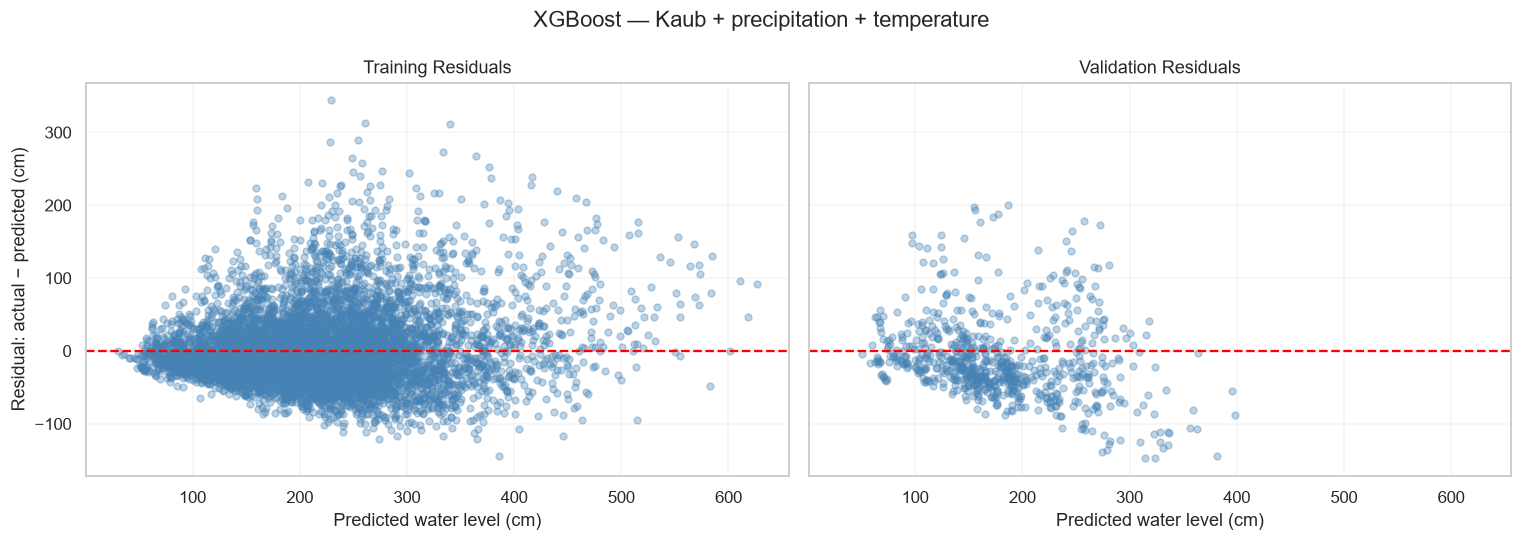

In [64]:

# Select the model with the lowest validation MAE
best_group = xgb_results_df.loc[
    xgb_results_df["MAE"].idxmin(), "Feature group"
]

best_model = xgb_models[best_group]
columns = best_model.get_booster().feature_names

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    sharex=True, sharey=True
)

for ax, (name, dataset) in zip(
    axes,
    [("Training", train_fit), ("Validation", validation)]
):
    # Predict using the same model and training features
    predictions = best_model.predict(dataset[columns])

    # Positive = underprediction; negative = overprediction
    residuals = dataset["target"].to_numpy() - predictions

    ax.scatter(
        predictions, residuals,
        alpha=0.35, s=20, color="steelblue"
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{name} Residuals")
    ax.set_xlabel("Predicted water level (cm)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Residual: actual − predicted (cm)")

fig.suptitle(f"XGBoost — {best_group}")
plt.tight_layout()
plt.show()

In [65]:
# 1. Define thresholds using training targets only
low_threshold = train_fit["target"].quantile(0.10)
high_threshold = train_fit["target"].quantile(0.90)

print(f"Low-water threshold: {low_threshold:.1f} cm")
print(f"High-water threshold: {high_threshold:.1f} cm")

# 2. Predict validation water levels
columns = best_model.get_booster().feature_names

extreme_analysis = pd.DataFrame({
    "actual": validation["target"],
    "predicted": best_model.predict(validation[columns])
})

# Classify conditions using ACTUAL water levels
extreme_analysis["condition"] = np.select(
    [
        extreme_analysis["actual"] <= low_threshold,
        extreme_analysis["actual"] >= high_threshold
    ],
    ["Low water", "High water"],
    default="Normal range"
)

# Positive error means overprediction
extreme_analysis["error"] = (
    extreme_analysis["predicted"] - extreme_analysis["actual"]
)

# Persistence predicts the current level for the future target
extreme_analysis["persistence"] = validation["lag_0"]

# 3. Compare performance by water condition
results = []

for condition in ["Low water", "Normal range", "High water"]:
    subset = extreme_analysis[
        extreme_analysis["condition"] == condition
    ]

    if subset.empty:
        continue

    error = subset["error"]
    mae = error.abs().mean()

    baseline_mae = (
        subset["persistence"] - subset["actual"]
    ).abs().mean()

    results.append({
        "Condition": condition,
        "Days": len(subset),
        "MAE (cm)": mae,
        "RMSE (cm)": np.sqrt((error ** 2).mean()),
        "Bias (cm)": error.mean(),
        "Overprediction (%)": (error > 0).mean() * 100,
        "Persistence MAE (cm)": baseline_mae,
        "Skill vs persistence": (
            1 - mae / baseline_mae
            if baseline_mae > 0 else np.nan
        )
    })

extreme_results = pd.DataFrame(results)
display(extreme_results.round(2))

Low-water threshold: 110.0 cm
High-water threshold: 349.0 cm


,Condition,Days,MAE (cm),RMSE (cm),Bias (cm),Overprediction (%),Persistence MAE (cm),Skill vs persistence
0,Low water,155,31.49,37.92,26.86,85.16,19.74,-0.6
1,Normal range,554,43.41,54.64,12.41,65.70,48.43,0.1
2,High water,21,133.86,143.12,-133.53,4.76,149.33,0.1


Polynomial Features

In [66]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures

# Store transformed datasets and fitted transformers
poly_data = {}
poly_transformers = {}

for group_name, columns in feature_groups.items():

    # Degree 2: original features + squares + pairwise interactions
    # Exclude the constant column
    poly = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    # Fit on training data; apply the same transformation to validation
    X_train_poly = poly.fit_transform(train_fit[columns])
    X_valid_poly = poly.transform(validation[columns])

    feature_names = poly.get_feature_names_out(columns)

    # Convert to DataFrames, preserving dates and feature names
    poly_data[group_name] = {
        "train": pd.DataFrame(
            X_train_poly,
            columns=feature_names,
            index=train_fit.index
        ),
        "validation": pd.DataFrame(
            X_valid_poly,
            columns=feature_names,
            index=validation.index
        )
    }

    poly_transformers[group_name] = poly

    print(
        f"{group_name}: "
        f"{len(columns)} original → "
        f"{len(feature_names)} polynomial features"
    )

Kaub only: 7 original → 35 polynomial features
Kaub + precipitation: 11 original → 77 polynomial features
Kaub + precipitation + temperature: 13 original → 104 polynomial features
All selected features: 18 original → 189 polynomial features


In [67]:
group = "Kaub + precipitation + temperature"

print(poly_data[group]["train"].columns.tolist())
display(poly_data[group]["train"].head())

['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d', 'lag_0^2', 'lag_0 lag_1', 'lag_0 lag_2', 'lag_0 lag_3', 'lag_0 lag_7', 'lag_0 lag_14', 'lag_0 lag_28', 'lag_0 precip_3d', 'lag_0 precip_7d', 'lag_0 precip_14d', 'lag_0 precip_30d', 'lag_0 temp_3d', 'lag_0 temp_7d', 'lag_1^2', 'lag_1 lag_2', 'lag_1 lag_3', 'lag_1 lag_7', 'lag_1 lag_14', 'lag_1 lag_28', 'lag_1 precip_3d', 'lag_1 precip_7d', 'lag_1 precip_14d', 'lag_1 precip_30d', 'lag_1 temp_3d', 'lag_1 temp_7d', 'lag_2^2', 'lag_2 lag_3', 'lag_2 lag_7', 'lag_2 lag_14', 'lag_2 lag_28', 'lag_2 precip_3d', 'lag_2 precip_7d', 'lag_2 precip_14d', 'lag_2 precip_30d', 'lag_2 temp_3d', 'lag_2 temp_7d', 'lag_3^2', 'lag_3 lag_7', 'lag_3 lag_14', 'lag_3 lag_28', 'lag_3 precip_3d', 'lag_3 precip_7d', 'lag_3 precip_14d', 'lag_3 precip_30d', 'lag_3 temp_3d', 'lag_3 temp_7d', 'lag_7^2', 'lag_7 lag_14', 'lag_7 lag_28', 'lag_7 precip_3d', 'lag_7 precip_7d', 'lag_7 

,lag_0,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,precip_3d,precip_7d,precip_14d,...,precip_14d^2,precip_14d precip_30d,precip_14d temp_3d,precip_14d temp_7d,precip_30d^2,precip_30d temp_3d,precip_30d temp_7d,temp_3d^2,temp_3d temp_7d,temp_7d^2
date,,,,,,,,,,,,,,,,,,,,,
2000-01-30,187.0,168.0,173.0,180.0,202.0,238.0,401.0,14.0,14.0,26.0,...,676.0,962.0,104.000000,-22.285714,1369.0,148.000000,-31.714286,16.000000,-3.428571,0.734694
2000-01-31,245.0,187.0,168.0,173.0,205.0,226.0,368.0,14.0,14.0,26.0,...,676.0,910.0,182.000000,26.000000,1225.0,245.000000,35.000000,49.000000,7.000000,1.000000
2000-02-01,363.0,245.0,187.0,168.0,200.0,214.0,346.0,6.0,14.0,25.0,...,625.0,875.0,191.666667,75.000000,1225.0,268.333333,105.000000,58.777778,23.000000,9.000000
2000-02-02,396.0,363.0,245.0,187.0,192.0,208.0,328.0,3.0,17.0,28.0,...,784.0,1064.0,196.000000,124.000000,1444.0,266.000000,168.285714,49.000000,31.000000,19.612245
2000-02-03,367.0,396.0,363.0,245.0,180.0,206.0,311.0,4.0,18.0,29.0,...,841.0,1102.0,164.333333,153.285714,1444.0,215.333333,200.857143,32.111111,29.952381,27.938776


In [68]:
for column in poly_data[group]["train"].columns:
    print(column)

lag_0
lag_1
lag_2
lag_3
lag_7
lag_14
lag_28
precip_3d
precip_7d
precip_14d
precip_30d
temp_3d
temp_7d
lag_0^2
lag_0 lag_1
lag_0 lag_2
lag_0 lag_3
lag_0 lag_7
lag_0 lag_14
lag_0 lag_28
lag_0 precip_3d
lag_0 precip_7d
lag_0 precip_14d
lag_0 precip_30d
lag_0 temp_3d
lag_0 temp_7d
lag_1^2
lag_1 lag_2
lag_1 lag_3
lag_1 lag_7
lag_1 lag_14
lag_1 lag_28
lag_1 precip_3d
lag_1 precip_7d
lag_1 precip_14d
lag_1 precip_30d
lag_1 temp_3d
lag_1 temp_7d
lag_2^2
lag_2 lag_3
lag_2 lag_7
lag_2 lag_14
lag_2 lag_28
lag_2 precip_3d
lag_2 precip_7d
lag_2 precip_14d
lag_2 precip_30d
lag_2 temp_3d
lag_2 temp_7d
lag_3^2
lag_3 lag_7
lag_3 lag_14
lag_3 lag_28
lag_3 precip_3d
lag_3 precip_7d
lag_3 precip_14d
lag_3 precip_30d
lag_3 temp_3d
lag_3 temp_7d
lag_7^2
lag_7 lag_14
lag_7 lag_28
lag_7 precip_3d
lag_7 precip_7d
lag_7 precip_14d
lag_7 precip_30d
lag_7 temp_3d
lag_7 temp_7d
lag_14^2
lag_14 lag_28
lag_14 precip_3d
lag_14 precip_7d
lag_14 precip_14d
lag_14 precip_30d
lag_14 temp_3d
lag_14 temp_7d
lag_28^2
lag_28

In [69]:
rows, columns = poly_data[group]["train"].shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 7872
Number of columns: 104


In [70]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

poly_results = []
poly_models = {}

for group, datasets in poly_data.items():

    X_train_poly = datasets["train"]
    X_val_poly = datasets["validation"]

    # Match targets to the feature rows using their original date index
    y_train_poly = train_fit.loc[X_train_poly.index, "target"]
    y_val_poly = validation.loc[X_val_poly.index, "target"]

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(X_train_poly, y_train_poly)
    predictions = model.predict(X_val_poly)

    mae = mean_absolute_error(y_val_poly, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_poly, predictions))
    r2 = r2_score(y_val_poly, predictions)
    bias = np.mean(predictions - y_val_poly.to_numpy())

    poly_results.append({
        "Feature group": group,
        "Number of features": X_train_poly.shape[1],
        "Validation MAE": mae,
        "Validation RMSE": rmse,
        "Validation R²": r2,
        "Validation Bias (cm)": bias
    })

    poly_models[group] = model

poly_results_df = (
    pd.DataFrame(poly_results)
    .sort_values("Validation MAE")
    .reset_index(drop=True)
)

display(poly_results_df.round(3))

,Feature group,Number of features,Validation MAE,Validation RMSE,Validation R²,Validation Bias (cm)
0,Kaub + precipitation + temperature,104,42.979,55.922,0.439,10.887
1,All selected features,189,43.534,56.437,0.428,12.796
2,Kaub only,35,45.063,57.604,0.404,10.342
3,Kaub + precipitation,77,45.470,59.232,0.370,11.995


In [71]:
# Polynomial Ridge results
poly_comparison = (
    poly_results_df[
        ["Feature group", "Validation MAE", "Validation RMSE"]
    ]
    .rename(columns={
        "Validation MAE": "MAE",
        "Validation RMSE": "RMSE"
    })
    .assign(Model="Polynomial Ridge")
)

# Original LightGBM results
lgbm_comparison = lgbm_results_df[
    ["Feature group", "MAE", "RMSE"]
].assign(Model="LightGBM")

# Random Forest results
rf_comparison = rf_results_df[
    ["Feature group", "MAE", "RMSE"]
].assign(Model="Random Forest")

# Combine model results
model_comparison = pd.concat(
    [poly_comparison, lgbm_comparison, rf_comparison],
    ignore_index=True
)

# Same validation persistence MAE for every model
model_comparison["Skill vs persistence (MAE)"] = (
    1 - model_comparison["MAE"] / persistence_mae
    if persistence_mae > 0 else np.nan
)

model_comparison = (
    model_comparison[
        ["Model", "Feature group", "MAE", "RMSE",
         "Skill vs persistence (MAE)"]
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(model_comparison.round(3))
print(f"Persistence validation MAE: {persistence_mae:.3f} cm")

,Model,Feature group,MAE,RMSE,Skill vs persistence (MAE)
0,Polynomial Ridge,Kaub + precipitation + temperature,42.979,55.922,0.154
1,Polynomial Ridge,All selected features,43.534,56.437,0.143
2,LightGBM,Kaub + precipitation + temperature,44.554,56.804,0.123
3,LightGBM,All selected features,44.758,57.161,0.119
4,Polynomial Ridge,Kaub only,45.063,57.604,0.113
5,Polynomial Ridge,Kaub + precipitation,45.470,59.232,0.105
6,Random Forest,Kaub + precipitation + temperature,45.497,57.900,0.105
7,LightGBM,Kaub + precipitation,45.955,58.727,0.096
8,Random Forest,Kaub only,46.592,59.908,0.083
9,Random Forest,All selected features,46.864,59.292,0.078


Persistence validation MAE: 50.816 cm


In [72]:
best_result = model_comparison.iloc[0]

print("Best model:", best_result["Model"])
print("Best feature group:", best_result["Feature group"])
print(f"Validation MAE: {best_result['MAE']:.3f} cm")

Best model: Polynomial Ridge
Best feature group: Kaub + precipitation + temperature
Validation MAE: 42.979 cm


# Error Analysis :

In [73]:
LOW_WATER_THRESHOLD = 77  # cm — replace with your chosen threshold

In [74]:
import numpy as np
import pandas as pd

# Replace these with your fitted model and its feature list
model = xgb_models["Kaub + precipitation + temperature"]
columns = feature_groups["Kaub + precipitation + temperature"]

def evaluate_water_errors(model, data, columns, dataset_name, threshold):
    actual = data["target"].to_numpy()
    predicted = model.predict(data[columns])

    # Positive error means OVERPREDICTION
    error = predicted - actual

    results = []

    for condition, mask in {
        "All levels": np.ones(len(actual), dtype=bool),
        "Low water": actual < threshold,
    }.items():

        if not mask.any():
            continue

        errors = error[mask]

        results.append({
            "Dataset": dataset_name,
            "Condition": condition,
            "Samples": int(mask.sum()),
            "MAE": np.mean(np.abs(errors)),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "Bias (predicted - actual)": np.mean(errors),
            "Overprediction (%)": 100 * np.mean(errors > 0),
            "Mean overprediction amount": np.maximum(errors, 0).mean(),
        })

    return pd.DataFrame(results)

results = pd.concat([
    evaluate_water_errors(
        model, train_fit, columns, "Training", LOW_WATER_THRESHOLD
    ),
    evaluate_water_errors(
        model, validation, columns, "Validation", LOW_WATER_THRESHOLD
    ),
], ignore_index=True)

display(results.round(2))

,Dataset,Condition,Samples,MAE,RMSE,Bias (predicted - actual),Overprediction (%),Mean overprediction amount
0,Training,All levels,7872,36.83,50.49,0.01,60.18,18.42
1,Training,Low water,290,20.54,24.28,19.59,92.07,20.07
2,Validation,All levels,730,43.48,56.21,11.28,68.08,27.38
3,Validation,Low water,50,23.58,27.49,23.15,96.00,23.36


In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

group = "Kaub + precipitation + temperature"
model = xgb_models[group]  # Use your chosen fitted model
columns = feature_groups[group]

H = 7
LOW_WATER_THRESHOLD = 77  # Example: use your agreed threshold

errors = pd.DataFrame({
    "Actual": validation["target"],
    "Predicted": model.predict(validation[columns]),
    "Persistence": validation["lag_0"],
})

# Assumes the validation index is the forecast origin date
errors.index.name = "Forecast_origin"
errors["Target_date"] = errors.index + pd.Timedelta(days=H)

# Positive = overprediction; negative = underprediction
errors["Error"] = errors["Predicted"] - errors["Actual"]
errors["Absolute_error"] = errors["Error"].abs()
errors["Persistence_absolute_error"] = (
    errors["Persistence"] - errors["Actual"]
).abs()

errors["Low_water"] = errors["Actual"] < LOW_WATER_THRESHOLD
errors["Overprediction"] = errors["Error"] > 0

display(errors.head().round(2))

C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_24220\1786249639.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(errors.head().round(2))


,Actual,Predicted,Persistence,Target_date,Error,Absolute_error,Persistence_absolute_error,Low_water,Overprediction
Forecast_origin,,,,,,,,,
2021-08-26,240,254.220001,237,2021-09-02,14.22,14.22,3,False,True
2021-08-27,225,253.020004,220,2021-09-03,28.02,28.02,5,False,True
2021-08-28,211,234.669998,212,2021-09-04,23.67,23.67,1,False,True
2021-08-29,202,229.380005,208,2021-09-05,27.38,27.38,6,False,True
2021-08-30,195,209.039993,212,2021-09-06,14.04,14.04,17,False,True


In [76]:
def summarize_errors(frame):
    if frame.empty:
        return pd.Series({"Samples": 0})

    baseline_mae = frame["Persistence_absolute_error"].mean()
    model_mae = frame["Absolute_error"].mean()

    return pd.Series({
        "Samples": len(frame),
        "MAE": model_mae,
        "RMSE": np.sqrt((frame["Error"] ** 2).mean()),
        "Bias": frame["Error"].mean(),
        "Overprediction_pct": 100 * frame["Overprediction"].mean(),
        "P90_absolute_error": frame["Absolute_error"].quantile(0.90),
        "Persistence_MAE": baseline_mae,
        "Skill_pct": (
            100 * (1 - model_mae / baseline_mae)
            if baseline_mae > 0 else np.nan
        ),
    })

summary = pd.DataFrame({
    "All levels": summarize_errors(errors),
    "Low water": summarize_errors(errors.loc[errors["Low_water"]]),
    "Other levels": summarize_errors(errors.loc[~errors["Low_water"]]),
}).T

display(summary.round(2))

,Samples,MAE,RMSE,Bias,Overprediction_pct,P90_absolute_error,Persistence_MAE,Skill_pct
All levels,730.0,43.48,56.21,11.28,68.08,88.77,45.24,3.88
Low water,50.0,23.58,27.49,23.15,96.00,41.71,14.62,-61.28
Other levels,680.0,44.94,57.76,10.41,66.03,92.32,47.49,5.36


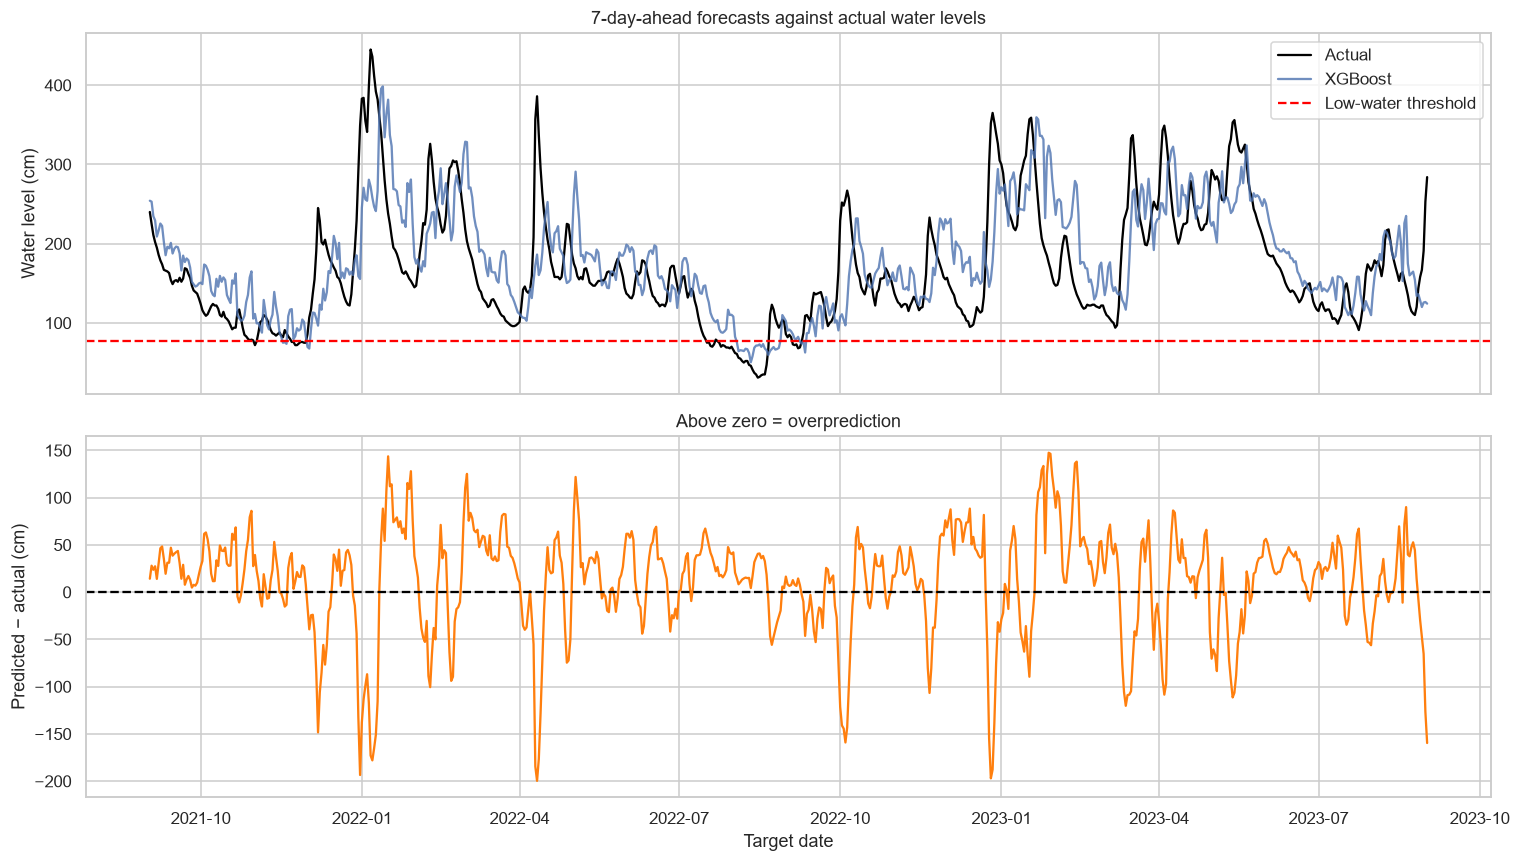

In [77]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    errors["Target_date"], errors["Actual"],
    label="Actual", color="black"
)
axes[0].plot(
    errors["Target_date"], errors["Predicted"],
    label="XGBoost", alpha=0.8
)
axes[0].axhline(
    LOW_WATER_THRESHOLD,
    color="red", linestyle="--", label="Low-water threshold"
)
axes[0].set_ylabel("Water level (cm)")
axes[0].set_title("7-day-ahead forecasts against actual water levels")
axes[0].legend()

axes[1].plot(
    errors["Target_date"], errors["Error"],
    color="tab:orange"
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Predicted − actual (cm)")
axes[1].set_xlabel("Target date")
axes[1].set_title("Above zero = overprediction")

plt.tight_layout()
plt.show()

In [78]:
worst_low_water = (
    errors.loc[errors["Low_water"] & errors["Overprediction"]]
    .nlargest(10, "Error")
)

display(
    worst_low_water[[
        "Target_date", "Actual", "Predicted",
        "Persistence", "Error"
    ]].round(2)
)

C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_24220\2420537319.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(2)


,Target_date,Actual,Predicted,Persistence,Error
Forecast_origin,,,,,
2022-07-10,2022-07-17,75,134.070007,128,59.07
2022-07-11,2022-07-18,76,125.980003,120,49.98
2022-07-22,2022-07-29,69,116.669998,79,47.67
2022-07-25,2022-08-01,66,108.099998,70,42.1
2022-07-23,2022-07-30,68,110.070000,77,42.07
2022-07-12,2022-07-19,71,112.669998,108,41.67
2021-11-15,2021-11-22,76,117.449997,88,41.45
2022-08-09,2022-08-16,32,72.919998,52,40.92
2022-08-08,2022-08-15,31,71.559998,52,40.56


Save Model for streamlit

In [79]:
import joblib
from pathlib import Path

# Select your trained model
best_group = "Kaub + precipitation + temperature"
model = xgb_models[best_group]

# Create a folder for saved models
Path("models").mkdir(parents=True, exist_ok=True)

# Save the model and its configuration
joblib.dump(
    {
        "model": model,
        "features": feature_groups[best_group],
        "horizon": H,
    },
    "models/kaub_xgboost.joblib"
)

print("Model saved successfully!")

Model saved successfully!
